In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, precision_score, confusion_matrix, recall_score
from sklearn.preprocessing import StandardScaler as SS
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier as KNN

In [9]:
df = pd.read_csv("diabetes.csv")
print(df.head())
print(df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  Pedigree  Age  Outcome
0            6      148             72             35        0  33.6     0.627   50        1
1            1       85             66             29        0  26.6     0.351   31        0
2            8      183             64              0        0  23.3     0.672   32        1
3            1       89             66             23       94  28.1     0.167   21        0
4            0      137             40             35      168  43.1     2.288   33        1
(768, 9)


In [10]:
X = df.drop("Outcome",axis = 1)
y = df["Outcome"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.18, random_state = 120, stratify = y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(629, 8)
(139, 8)
(629,)
(139,)


In [12]:
sc = SS()

In [13]:
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [14]:
knn = KNN(n_neighbors = 7)

In [16]:
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

In [17]:
cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("\nConfusion Matrix:\n", cm)
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Error Rate:", round(error_rate * 100, 2), "%")
print("Precision:", round(precision, 2))
print("Recall:", round(recall, 2))



Confusion Matrix:
 [[70 20]
 [21 28]]
Accuracy: 70.5 %
Error Rate: 29.5 %
Precision: 0.58
Recall: 0.57


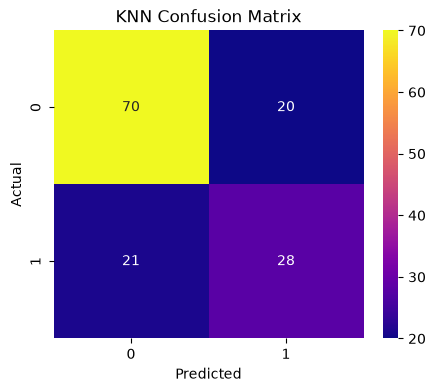

In [21]:

# 9. Display Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='plasma')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()
